# First real Lagos-area scene: engineering inspection

The input is a real contiguous Earth Engine Sentinel-1 acquisition, not the repeated-chip fixture. The exact date and orbit are recorded by the acquisition manifest. This checks acquisition, units, georeferencing and context sensitivity using the frozen model and threshold 0.55.

There are no independent labels here. Predicted water can include permanent water or model errors, so these images do not establish Nigerian segmentation accuracy, detected flooding, or a flood-risk probability. Comparing context margins does not by itself show which prediction is correct. Do not choose model settings from visually attractive results.

The notebook reads the small 1024×1024 scene for plotting. The inference command itself streams windows. Both context runs and the figure are saved; the main README includes the figure.

In [1]:
import os
import sys
from pathlib import Path

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT))


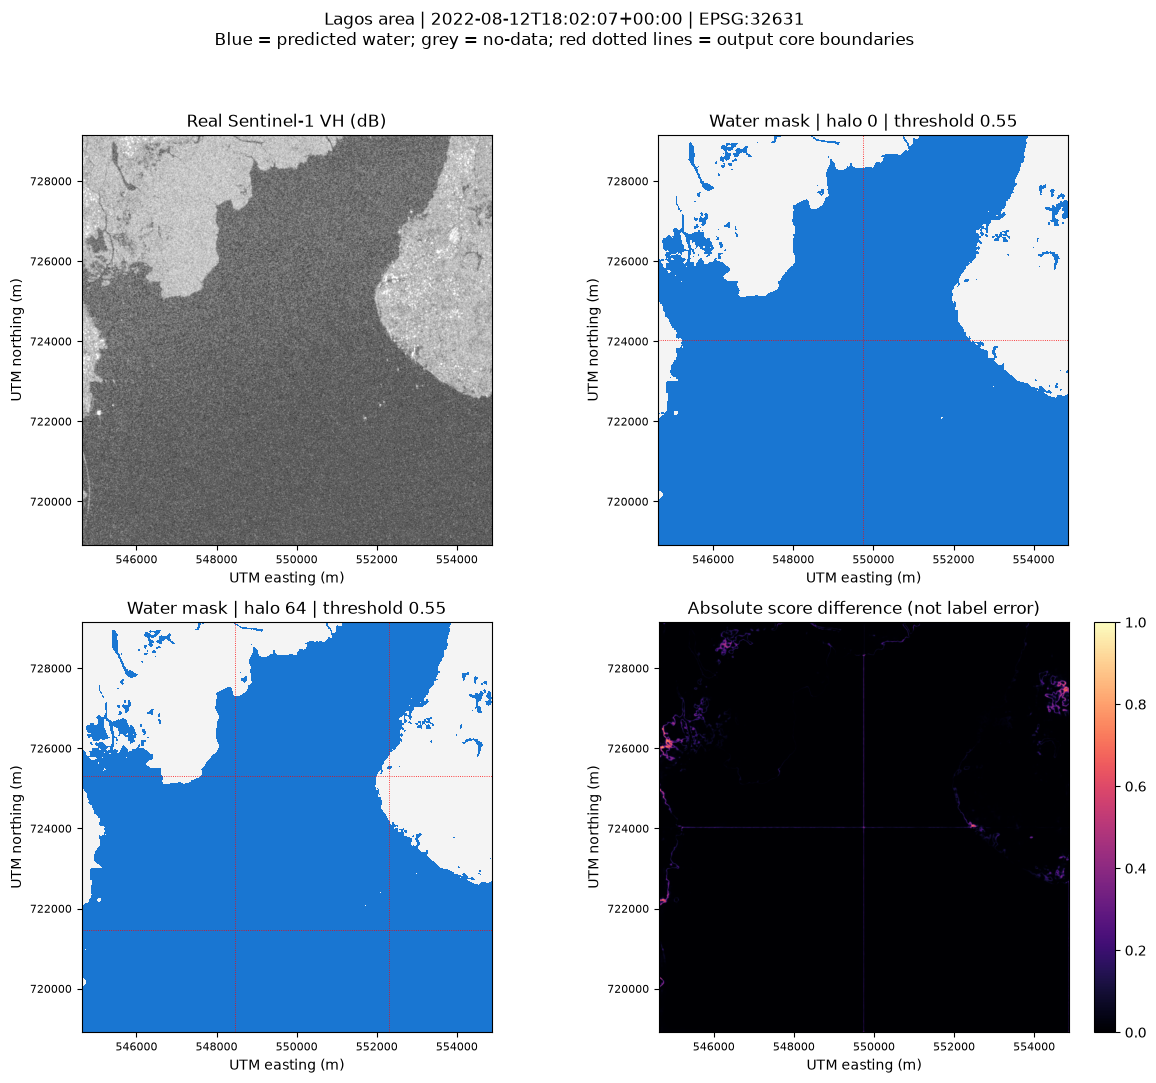

{
  "source_scene": {
    "instrumentMode": "IW",
    "orbitProperties_pass": "ASCENDING",
    "platform_number": "A",
    "relativeOrbitNumber_start": 1,
    "system:index": "S1A_IW_GRDH_1SDV_20220812T180207_20220812T180232_044523_055032_0565",
    "system:time_start": 1660327327000
  },
  "source_sha256": "1eff60b4d56fbef6856f2c48d3b0cdcb1f7a593eec5b5ebecf88ea69f6472b2c",
  "shape": [
    1024,
    1024
  ],
  "crs": "EPSG:32631",
  "pixel_size_m": 10,
  "valid_pixels": 1048576,
  "nodata_pixels": 0,
  "water_pixels": {
    "0": 783833,
    "64": 780904
  },
  "mask_disagreements": 3485,
  "mean_abs_score_difference": 0.004724170081317425,
  "bands": {
    "VV": {
      "min": -35.87677001953125,
      "max": 23.766294479370117,
      "percentiles_1_50_99": [
        -23.976787567138672,
        -17.342453956604004,
        -2.0057130455970764
      ]
    },
    "VH": {
      "min": -47.02043151855469,
      "max": 10.503278732299805,
      "percentiles_1_50_99": [
        -33.531314

In [2]:
import json
import shutil
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from floodrisk.deploy.tiled import predict_scene, file_hash

scene_dir = PROJECT / "data/scenes/lagos_2022"
source = scene_dir / "sentinel1_vv_vh_db.tif"
out = PROJECT / "reports/lagos_2022"
out.mkdir(exist_ok=True)
export = PROJECT / "reports/m1-s1-kaggle-365653491/onnx_fp32"
acquisition = json.loads((scene_dir / "acquisition.json").read_text())
assert file_hash(source) == acquisition["sha256"]
shutil.copy2(scene_dir / "acquisition.json", out / "acquisition.json")
for halo in [0,64]:
    destination = PROJECT / f"data/predictions/lagos_2022/halo_{halo}"
    if not destination.exists():
        predict_scene(source, export / "m1_s1_fp32.onnx", export / "inference_config.json", destination, halo=halo)
    shutil.copy2(destination / "prediction.json", out / f"halo_{halo}_prediction.json")
with rasterio.open(source) as src:
    raw = src.read(masked=True)
    bounds = src.bounds
    extent = [bounds.left,bounds.right,bounds.bottom,bounds.top]
    transform,crs,shape = src.transform,src.crs,src.shape
scores,masks = {},{}
for halo in [0,64]:
    destination = PROJECT / f"data/predictions/lagos_2022/halo_{halo}"
    for filename,store in [("water_score.tif",scores),("water_mask.tif",masks)]:
        with rasterio.open(destination / filename) as dst:
            assert dst.transform == transform and dst.crs == crs and dst.shape == shape
            store[halo] = dst.read(1,masked=True)
valid = ~np.ma.getmaskarray(scores[0])
assert np.array_equal(valid,~np.ma.getmaskarray(scores[64]))
assert valid.sum() > 0
summary = dict(source_scene=acquisition["source"], source_sha256=file_hash(source),
    shape=list(shape), crs=str(crs), pixel_size_m=10,
    valid_pixels=int(valid.sum()), nodata_pixels=int((~valid).sum()),
    water_pixels={str(h):int(((masks[h].data==1)&valid).sum()) for h in [0,64]},
    mask_disagreements=int(((masks[0].data!=masks[64].data)&valid).sum()),
    mean_abs_score_difference=float(np.ma.abs(scores[0]-scores[64]).mean()),
    bands={name:dict(min=float(raw[i].min()),max=float(raw[i].max()),
                    percentiles_1_50_99=np.percentile(raw[i].compressed(),[1,50,99]).tolist())
           for i,name in enumerate(["VV","VH"])},
    interpretation="Unlabelled real-scene context sensitivity; no segmentation accuracy or flood-event claim")
(out / "inspection.json").write_text(json.dumps(summary,indent=2)+"\n")
fig,axes = plt.subplots(2,2,figsize=(12,11))
axes[0,0].imshow(raw[1],cmap="gray",vmin=-42,vmax=-5,extent=extent)
axes[0,0].set_title("Real Sentinel-1 VH (dB)")
cmap = ListedColormap(["#f4f4f4","#1976d2"]);cmap.set_bad("#bcbcbc")
for ax,halo in [(axes[0,1],0),(axes[1,0],64)]:
    ax.imshow(masks[halo],cmap=cmap,vmin=0,vmax=1,extent=extent,interpolation="nearest")
    core = 512-2*halo
    for x in range(core,shape[1],core): ax.axvline(transform.c+x*10,color="red",linestyle=":",linewidth=0.6)
    for y in range(core,shape[0],core): ax.axhline(transform.f-y*10,color="red",linestyle=":",linewidth=0.6)
    ax.set_title(f"Water mask | halo {halo} | threshold 0.55")
image = axes[1,1].imshow(np.ma.abs(scores[0]-scores[64]),cmap="magma",vmin=0,vmax=1,extent=extent)
axes[1,1].set_title("Absolute score difference (not label error)")
fig.colorbar(image,ax=axes[1,1],fraction=0.046)
for ax in axes.flat:
    ax.set_xlabel("UTM easting (m)");ax.set_ylabel("UTM northing (m)")
    ax.ticklabel_format(useOffset=False,style="plain");ax.tick_params(labelsize=8)
from datetime import datetime,timezone
acquired = datetime.fromtimestamp(acquisition["source"]["system:time_start"]/1000,timezone.utc).isoformat()
fig.suptitle(f"Lagos area | {acquired} | {crs}\nBlue = predicted water; grey = no-data; red dotted lines = output core boundaries")
fig.tight_layout(rect=[0,0,1,0.95]);fig.savefig(out / "lagos_context_comparison.png",dpi=160,bbox_inches="tight")
plt.show();plt.close(fig)
print(json.dumps(summary,indent=2))
